# [ENCODE](https://www.encodeproject.org/): Mus musculus mESC (ES-Bruce4) Histone

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-10-09
> - Modified: 2025-05-10

# 1. Experimental Design

| Marks | Function | Chromatin Status |
| - | - | - |
| **H3K4me3** | Promoter / TSS | Active |
| **H3K4me1** | Enhancer | Enhancer-associated / Poised |
| **H3K27ac** | Active enhancer / Promoter | Active |
| **H3K9ac** | Promoter / regulatory region | Active |
| **H3K36me3** | Gene body, especially 3′ region | Transcriptional elongation |
| **H3K27me3** | Polycomb-repressed promoters / domains | Repressed |
| **H3K9me3** | Heterochromatin / repetitive regions | Repressed / Heterochromatic |

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(EnrichedHeatmap)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- path.expand(
    "~/dataset_2/database/ENCODE/Mus_musculus/ES-Bruce4"
)

# 2. Data Import

In [3]:
MARKS <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K27me3", "H3K9ac", "H3K9me3", "H3K36me3"
)

## 1). Reference Resources

In [ ]:
suppressPackageStartupMessages({
    library(TxDb.Mmusculus.UCSC.mm10.knownGene)
    library(BSgenome.Mmusculus.UCSC.mm10)
    library(org.Mm.eg.db)
})

txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene
genome <- BSgenome.Mmusculus.UCSC.mm10

## 2). Blacklist Region

In [5]:
blacklist_file <- path.expand(
    "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"
)

## 3). narrowPeak Import

In [6]:
load_peaks <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL, format = "auto") {

    if (format == "auto") {
        if (grepl("\\.narrowPeak$", file)) {
            format <- "narrowPeak"
        } else if (grepl("\\.broadPeak$", file)) {
            format <- "broadPeak"
        } else if (grepl("\\.gappedPeak$", file)) {
            format <- "gappedPeak"
        } else {
            format <- "BED"
        }
    }

    gr <- rtracklayer::import(file, format = format)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY", "X", "Y"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist region (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [7]:
peaks_files <- file.path(data_dir, "bed") |>
    list.files(pattern = "\\.bed$", full.names = TRUE) |>
    set_names(~ sub("^ESC_([^_]+)_.*$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |>
    cat(sep = "\n")

H3K27ac: ESC_H3K27ac_ENCFF274UIB.bed
H3K27me3: ESC_H3K27me3_ENCFF008XKX.bed
H3K36me3: ESC_H3K36me3_ENCFF872CBV.bed
H3K4me1: ESC_H3K4me1_ENCFF426IIV.bed
H3K4me3: ESC_H3K4me3_ENCFF974BMC.bed
H3K9ac: ESC_H3K9ac_ENCFF514APY.bed
H3K9me3: ESC_H3K9me3_ENCFF348IAW.bed


In [8]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    format = "narrowPeak")

peaks_list <- peaks_list[MARKS]

peaks_list[1]

$H3K4me3
GRanges object with 49579 ranges and 6 metadata columns:
          seqnames            ranges strand |        name     score signalValue
             <Rle>         <IRanges>  <Rle> | <character> <numeric>   <numeric>
      [1]     chr1 10008752-10009380      * |  Peak_23885       428    11.23695
      [2]     chr1 10009664-10009896      * |  Peak_50994        75     3.00446
      [3]     chr1 10037300-10038732      * |    Peak_214      1000    37.07471
      [4]     chr1 10038883-10039286      * |  Peak_22909       469     9.20144
      [5]     chr1 10039462-10039636      * |  Peak_35096       176     4.65032
      ...      ...               ...    ... .         ...       ...         ...
  [49575]     chrX 99821367-99821966      * |  Peak_25922       358    13.46649
  [49576]     chrX 99853404-99854013      * |  Peak_14214      1000    27.54683
  [49577]     chrX 99975596-99976739      * |  Peak_15721       946    28.44460
  [49578]     chrY   1010646-1010833      * |  Peak_38

## 4). bigwig Import

In [9]:
load_bigwig <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY", "X", "Y"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [ ]:
signals_files <- file.path(data_dir, "bigwig") |>
    list.files(pattern = "\\.(bigWig|bw)$", full.names = TRUE) |>
    set_names(~ sub("^ESC_([^_]+)_.*$", "\\1", basename(.x)))

paste(names(signals_files), basename(signals_files), sep = ": ") |>
    cat(sep = "\n")

H3K27ac: ESC_H3K27ac_ENCFF121THA.bigWig
H3K27me3: ESC_H3K27me3_ENCFF160FEV.bigWig
H3K36me3: ESC_H3K36me3_ENCFF827DUA.bigWig
H3K4me1: ESC_H3K4me1_ENCFF853NHQ.bigWig
H3K4me3: ESC_H3K4me3_ENCFF783OPZ.bigWig
H3K9ac: ESC_H3K9ac_ENCFF510LJS.bigWig
H3K9me3: ESC_H3K9me3_ENCFF162CRL.bigWig


In [11]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file)

signals_list <- signals_list[MARKS]

signals_list[1]

$H3K4me3
GRanges object with 67849485 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3003253      * |   0.09169
         [2]     chr1   3003254-3003263      * |   0.05884
         [3]     chr1   3003264-3003309      * |   0.02005
         [4]     chr1   3003310-3003311      * |   0.05884
         [5]     chr1   3003312-3003319      * |   0.02005
         ...      ...               ...    ... .       ...
  [67849481]     chrY 41132197-41132323      * |   0.05884
  [67849482]     chrY 41132324-41138559      * |   0.09169
  [67849483]     chrY 41138560-41138682      * |   0.05884
  [67849484]     chrY 41138683-41147243      * |   0.09169
  [67849485]     chrY 41147244-41147277      * |   0.05884
  -------
  seqinfo: 21 sequences from an unspecified genome


# 3. Quality Control

In [12]:
EFFECTIVE_GENOME_SIZE <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrM")) |>
    seqlengths() |>
    sum()

In [13]:
peaks_stats <- map_dfr(names(peaks_list), function(idx) {
    peaks <- peaks_list[[idx]]
    data.frame(
        mark = idx, 
        number_peak = length(peaks),
        min_width = min(width(peaks)),
        max_width = max(width(peaks)),
        mean_width = mean(width(peaks)),
        median_width = median(width(peaks)),
        genome_coverage = sum(width(peaks))
    )
}) |> 
    mutate(
        mark = factor(mark, levels = MARKS), 
        genome_coverage = round(
            genome_coverage / EFFECTIVE_GENOME_SIZE * 100, 2))

peaks_stats

mark,number_peak,min_width,max_width,mean_width,median_width,genome_coverage
<fct>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
H3K4me3,49579,130,5929,628.4736,469,1.14
H3K4me1,43122,115,1611,254.6657,221,0.40
H3K27ac,48676,153,8089,612.3450,448,1.09
H3K27me3,12466,110,3119,342.1604,248,0.16
H3K9ac,30956,243,11303,1195.9164,954,1.36
H3K9me3,39131,153,11410,511.9000,400,0.73
H3K36me3,80273,160,16893,602.8192,412,1.78


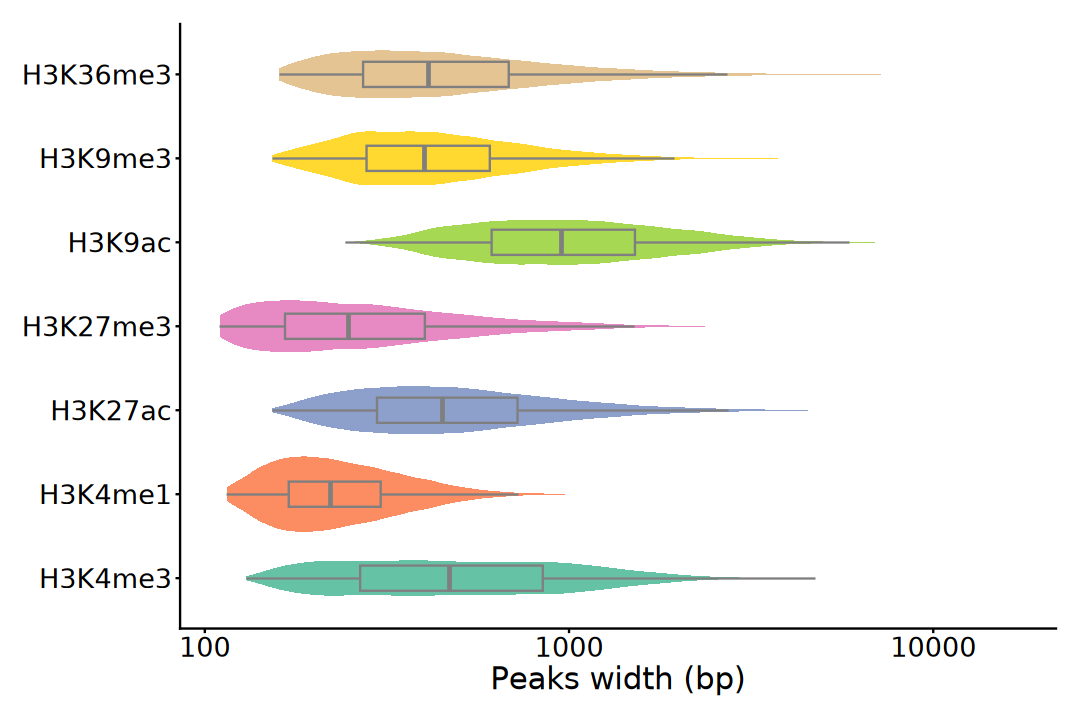

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_dfr(names(peaks_list), function(idx) {
    tibble(mark = idx, width = width(peaks_list[[idx]]))
}) |>
    mutate(mark = factor(mark, levels = MARKS)) |>
ggplot(aes(x = mark, y = width, fill = mark)) +
    geom_violin(trim = TRUE, color = NA) +
    geom_boxplot(width = 0.3, color = "grey50", outliers = FALSE) +
    scale_y_log10() +
    coord_flip() +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Peaks width (bp)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [15]:
# Generate genomic bins (100 kb window)
genome_bins <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrX", "chrY", "chrM")) |>
    seqlengths() |>
    tileGenome(tilewidth = 1e5, cut.last.tile.in.chrom = TRUE)

genome_bins

GRanges object with 24639 ranges and 0 metadata columns:
          seqnames            ranges strand
             <Rle>         <IRanges>  <Rle>
      [1]     chr1          1-100000      *
      [2]     chr1     100001-200000      *
      [3]     chr1     200001-300000      *
      [4]     chr1     300001-400000      *
      [5]     chr1     400001-500000      *
      ...      ...               ...    ...
  [24635]    chr19 61000001-61100000      *
  [24636]    chr19 61100001-61200000      *
  [24637]    chr19 61200001-61300000      *
  [24638]    chr19 61300001-61400000      *
  [24639]    chr19 61400001-61431566      *
  -------
  seqinfo: 19 sequences from an unspecified genome

In [16]:
# NOTE: Importing genome-wide bins as a NumericList expands the signal into
# per-base numeric vectors, which can be slow and memory-intensive.
# Reuse the imported GRanges and calculate overlap-length-weighted means
# to avoid repeated file I/O and per-base expansion.
# ~ 7 minutes, 32G memory
# bin_means_df <- purrr::map(signals_files, function(file) {
#     import(BigWigFile(file), which = genome_bins, as = "NumericList") |>
#         mean(na.rm = TRUE) |>
#         tidyr::replace_na(0)
# }) |> as.data.frame()

In [17]:
get_bin_means <- function(gr, bins, ignore.strand = TRUE) {
    stopifnot("score" %in% names(mcols(gr)))

    out <- numeric(length(bins))

    hits <- findOverlaps(bins, gr, ignore.strand = ignore.strand)

    if (length(hits) == 0L) return(out)

    i <- queryHits(hits)
    j <- subjectHits(hits)

    overlap_widths <- pmin(end(bins)[i], end(gr)[j]) -
        pmax(start(bins)[i], start(gr)[j]) + 1L

    scores <- gr$score[j]
    denominators <- as.numeric(width(bins))

    if (anyNA(scores)) {
        missing <- is.na(scores)

        missing_widths <- rowsum(
            overlap_widths[missing], group = i[missing], reorder = FALSE
        )

        missing_idx <- as.integer(rownames(missing_widths))

        denominators[missing_idx] <- denominators[missing_idx] -
            missing_widths[, 1L]

        scores[missing] <- 0
    }

    signal_sums <- rowsum(
        scores * overlap_widths, group = i, reorder = FALSE
    )

    idx <- as.integer(rownames(signal_sums))

    out[idx] <- signal_sums[, 1L] / denominators[idx]

    out[is.na(out)] <- 0

    return(out)
}

In [18]:
bin_means_df <- signals_list |>
    lapply(get_bin_means, bins = genome_bins) |>
    as.data.frame(check.names = FALSE)

In [19]:
bin_means_df <- as.data.frame(genome_bins) |>
    dplyr::bind_cols(bin_means_df[MARKS])

dim(bin_means_df)
head(bin_means_df)

[1] 24639    12

,seqnames,start,end,width,strand,H3K4me3,H3K4me1,H3K27ac,H3K27me3,H3K9ac,H3K9me3,H3K36me3
,<fct>,<int>,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr1,1,100000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921
2,chr1,100001,200000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921
3,chr1,200001,300000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921
4,chr1,300001,400000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921
5,chr1,400001,500000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921
6,chr1,500001,600000,100000,*,0.09169,0.26647,0.1399,0.12988,0.02694,0.08637,0.02921


In [20]:
signal_mat <- as.matrix(bin_means_df[, MARKS, drop = FALSE])

rownames(signal_mat) <- paste0(
    bin_means_df$seqnames, ":",
    bin_means_df$start, "-",
    bin_means_df$end
)

keep <- rowSums(!is.finite(signal_mat)) == 0L & rowSums(signal_mat != 0) > 0L

signal_mat <- signal_mat[keep, , drop = FALSE]

dim(signal_mat)

[1] 23888     7

In [21]:
cor_mat <- cor(signal_mat, method = "spearman")

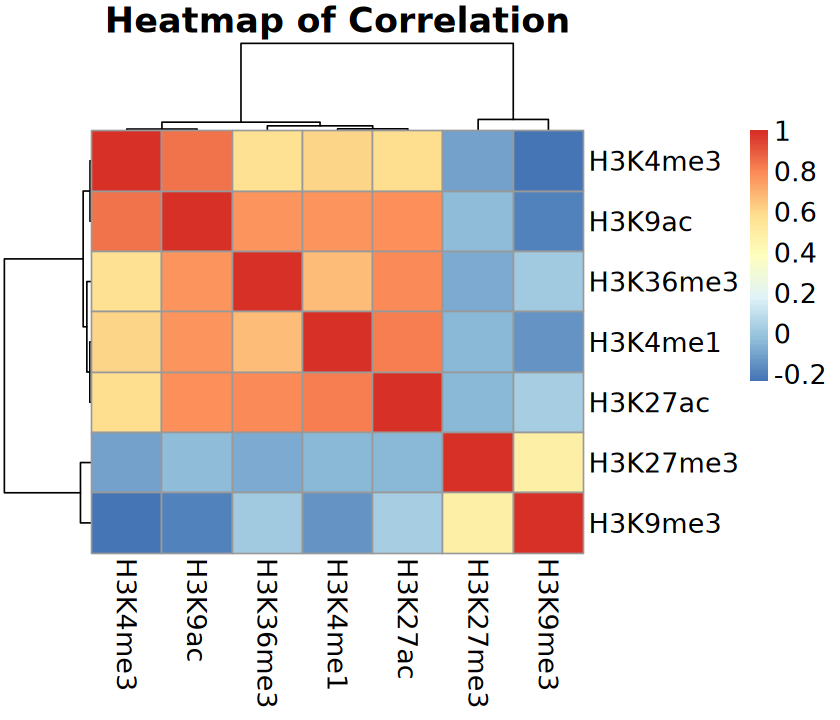

In [22]:
options(repr.plot.width = 7, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = TRUE, show_rownames = TRUE)

In [23]:
pca <- signal_mat |> log1p() |> scale() |> t() |>
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(pca$sdev^2 / sum(pca$sdev^2) * 100, 2)

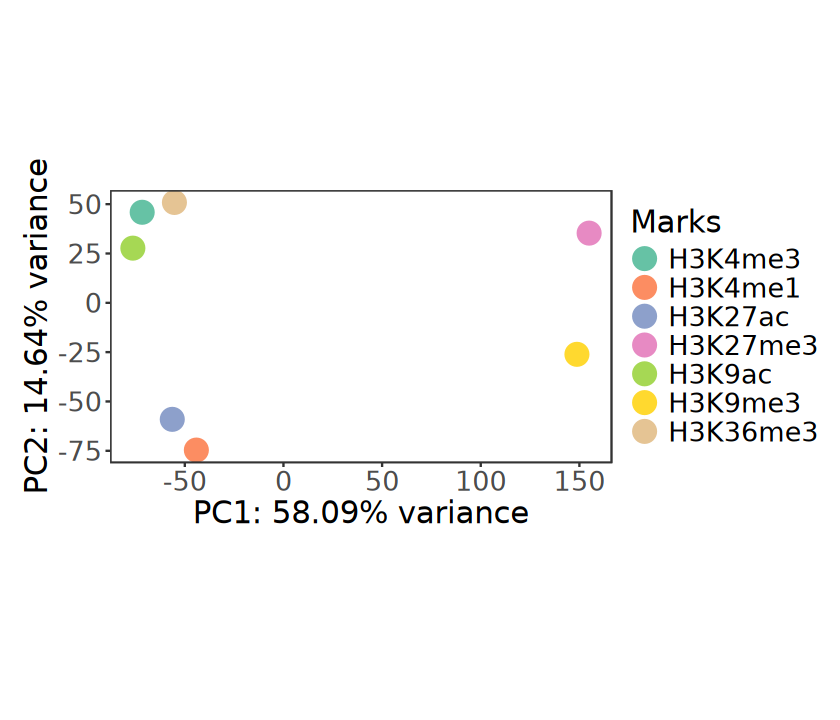

In [24]:
options(repr.plot.width = 7, repr.plot.height = 6)

pca$x |>
    as.data.frame() |>
    rownames_to_column(var = "marks") |>
    mutate(marks = factor(marks, levels = MARKS)) |>
ggplot(aes(PC1, PC2, color = marks)) +
    geom_point(size = 6) +
    coord_fixed() +
    scale_color_brewer(palette = "Set2") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    labs(color = "Marks") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [25]:
signal_norm <- signal_mat |> log1p() |> scale()

bin_var <- matrixStats::rowVars(signal_norm)

top_idx <- kit::topn(bin_var, n = 5000L, decreasing = TRUE)

selected <- top_idx[bin_var[top_idx] > 0]

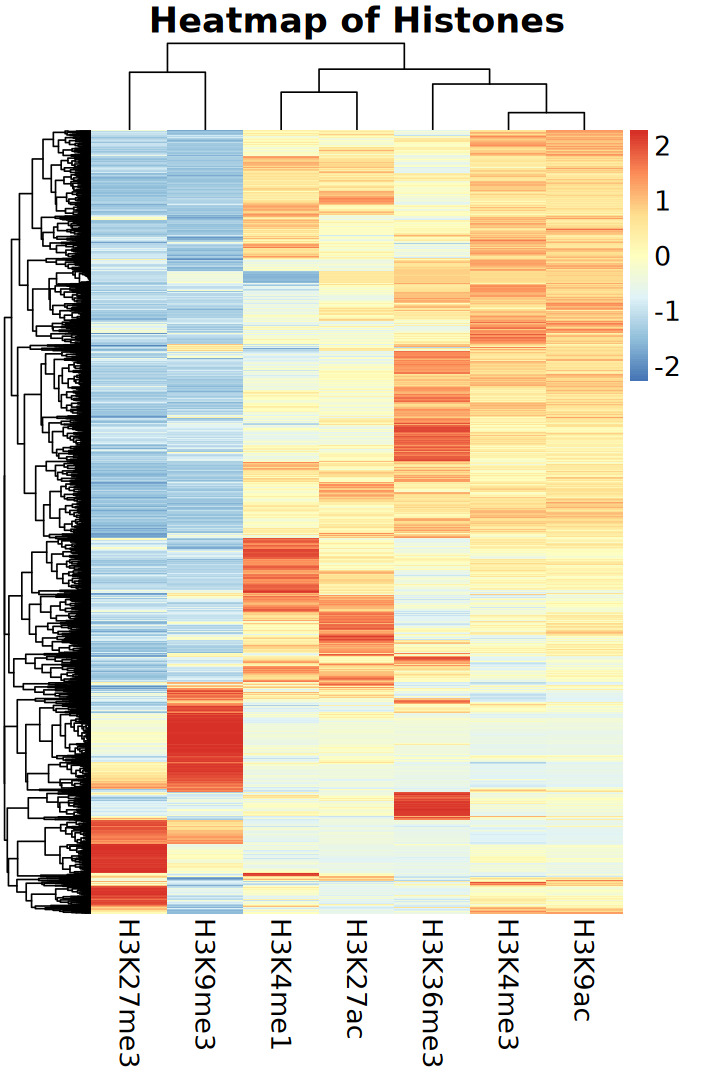

In [26]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    signal_norm[selected, ], 
    scale = "row", 
    show_colnames = TRUE, 
    show_rownames = FALSE, 
    fontsize = 16, 
    main = "Heatmap of Histones"
)

## 2). Genomics Circular

### a). circlize

> circular visualization in R
> - Zuguang Gu, Lei Gu, Roland Eils, Matthias Schlesner, Benedikt Brors, circlize implements and enhances circular visualization in R , Bioinformatics, Volume 30, Issue 19, October 2014, Pages 2811–2812, https://doi.org/10.1093/bioinformatics/btu393.

In [27]:
suppressPackageStartupMessages(library(circlize))

In [28]:
# Generate genomic bins (1Mb window)
genome_bins <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrM")) |>
    seqlengths() |>
    tileGenome(tilewidth = 1e6, cut.last.tile.in.chrom = TRUE)

chromosomes <- seqlevels(genome_bins)

In [29]:
# Count the number of genes in each bin
genome_bins$gene_density <- countOverlaps(
    genome_bins, genes(txdb)
) / (width(genome_bins) / 1e6)

  66 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [30]:
bin_df <- bind_cols(
    genome_bins |> 
        as.data.frame() |>
        dplyr::select(chr = seqnames, start, end, gene_density),
    signals_list |>
        lapply(get_bin_means, bins = genome_bins) |>
        as.data.frame(check.names = FALSE)
) |>
    mutate(chr = factor(chr, levels = chromosomes)) |>
    arrange(chr, start, end)

head(bin_df)

,chr,start,end,gene_density,H3K4me3,H3K4me1,H3K27ac,H3K27me3,H3K9ac,H3K9me3,H3K36me3
,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr1,1,1000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
2,chr1,1000001,2000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
3,chr1,2000001,3000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
4,chr1,3000001,4000000,2,0.1914944,0.3233256,0.2142102,0.2883899,0.0749436,0.4665401,0.06197077
5,chr1,4000001,5000000,6,0.5286630,0.3641569,0.5302510,0.3251794,0.3692653,0.4332242,0.36821217
6,chr1,5000001,6000000,4,0.3156121,0.3269231,0.2688877,0.2858169,0.1746582,0.4725100,0.20447595


In [31]:
track_colors <- c(
    gene_density = "#2d1c9c",
    H3K4me3      = "#ff670f",
    H3K27me3     = "#81e72e",
    H3K9me3      = "#055202"
)

In [32]:
plot_signal_track <- function(
    data, colname, color, track_height = 0.1, use_log = FALSE) {

    track_df <- data[, c("chr", "start", "end", colname)]
    # track_df$start <- track_df$start - 1L

    values <- track_df[[colname]]
    if (use_log) values <- log1p(values)
    track_df[[colname]] <- values

    ymax <- max(values)
    if (ymax == 0) ymax <- 1

    circos.genomicTrack(
        track_df,
        ylim = c(0, ymax),
        track.height = track_height,
        bg.border = NA,
        panel.fun = function(region, value, ...) {
            circos.genomicLines(
                region, value,
                area = TRUE,
                baseline = 0,
                col = color,
                border = color,
                ...
            )
        }
    )
}

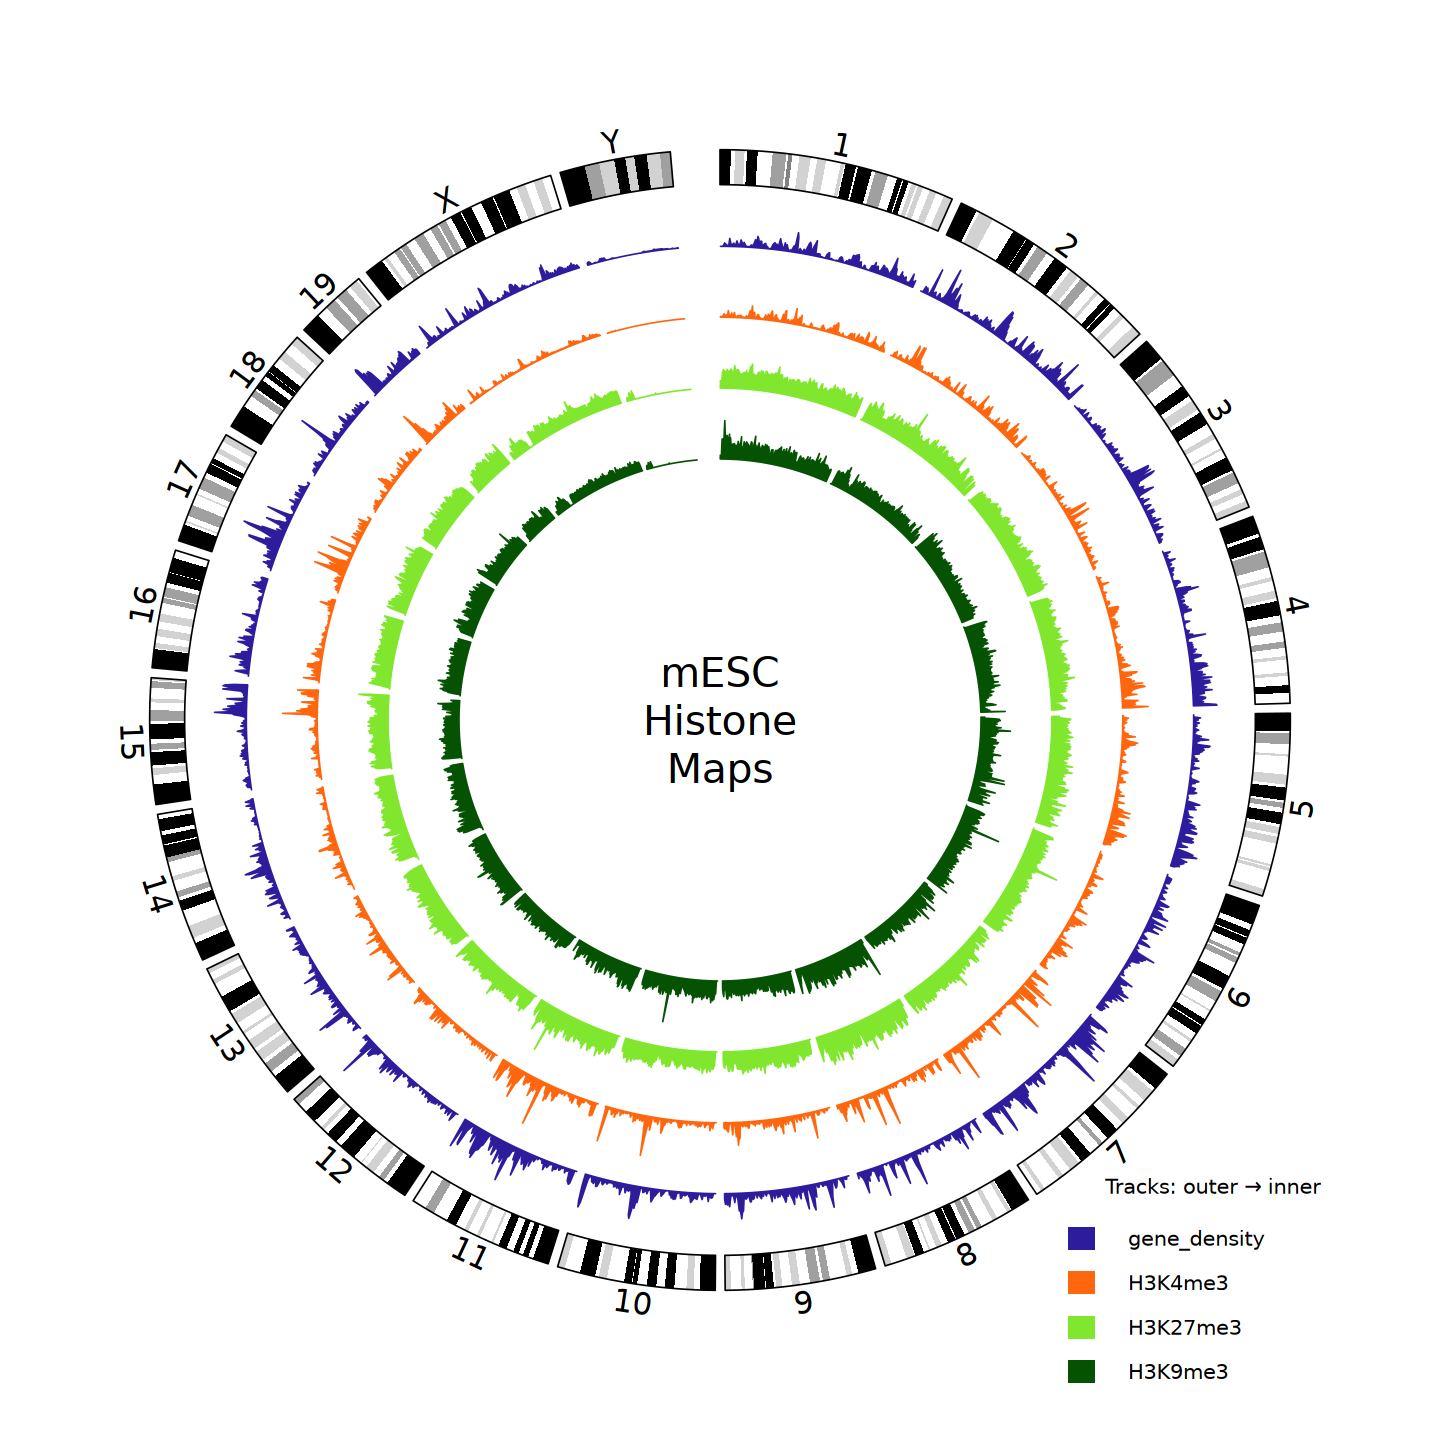

In [33]:
# Setup Circos plot parameters
options(repr.plot.width = 12, repr.plot.height = 12)

circos.clear()

circos.par(
    start.degree = 90, 
    track.margin = c(0.005, 0.005),
    gap.after = c(rep(1, length(chromosomes) - 1L), 5)
)

circos.initializeWithIdeogram(
    species = "mm10", 
    chromosome.index = chromosomes, 
    plotType = c("ideogram", "labels"), 
    ideogram.height = convert_height(4, "mm"),
    track.height = 0.1, 
    labels.cex = 1.5, 
    axis.labels.cex = 0.6
)

# Plot individual signal tracks
for (track in names(track_colors)) {
    plot_signal_track(
        data = bin_df, 
        colname = track,
        color = track_colors[[track]],
        use_log = FALSE
    )
}

# Add center annotation text
text(0, 0, "mESC\nHistone\nMaps", cex = 2)

# Add legend
legend(
    "bottomright", 
    horiz = FALSE, 
    legend = names(track_colors), 
    fill = unname(track_colors), 
    border = NA, 
    bty = "n", 
    cex = 1, 
    title = "Tracks: outer → inner"
)

circos.clear()

### b). RCircos

> RCircos is an easy-to-use R package for generating 2D circular (Circos) plots, widely used for visualizing genomic data. However, its rigid, hard-coded base graphics architecture substantially limits advanced customization and extensibility. Although custom rendering is still possible by overriding internal functions, doing so can be cumbersome and difficult to maintain.
> - Zhang, H., Meltzer, P. & Davis, S. RCircos: an R package for Circos 2D track plots. BMC Bioinformatics 14, 244 (2013). https://doi.org/10.1186/1471-2105-14-244

In [34]:
suppressPackageStartupMessages(library(RCircos))

In [35]:
# # Generate genomic bins (1Mb window)
# genome_bins <- seqinfo(genome) |>
#     keepStandardChromosomes() |>
#     dropSeqlevels(c("chrM")) |>
#     seqlengths() |>
#     tileGenome(tilewidth = 1e6, cut.last.tile.in.chrom = TRUE)

# chromosomes <- seqlevels(genome_bins)

In [36]:
# # Count the number of genes in each bin
# genome_bins$gene_density <- countOverlaps(
#     genome_bins, genes(txdb)
# ) / (width(genome_bins) / 1e6)

In [37]:
# bin_df <- bind_cols(
#     genome_bins |>
#         as.data.frame() |>
#         dplyr::select(
#             Chromosome = seqnames, chromStart = start, chromEnd = end, 
#             gene_density),
#     signals_list |>
#         lapply(get_bin_means, bins = genome_bins) |>
#         as.data.frame(check.names = FALSE)
# ) |>
#     mutate(Chromosome = factor(Chromosome, levels = chromosomes)) |>
#     arrange(Chromosome, chromStart, chromEnd)

bin_df <- bin_df |>
    dplyr::rename(Chromosome = chr, chromStart = start, chromEnd = end)

head(bin_df)

,Chromosome,chromStart,chromEnd,gene_density,H3K4me3,H3K4me1,H3K27ac,H3K27me3,H3K9ac,H3K9me3,H3K36me3
,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,chr1,1,1000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
2,chr1,1000001,2000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
3,chr1,2000001,3000000,0,0.0916900,0.2664700,0.1399000,0.1298800,0.0269400,0.0863700,0.02921000
4,chr1,3000001,4000000,2,0.1914944,0.3233256,0.2142102,0.2883899,0.0749436,0.4665401,0.06197077
5,chr1,4000001,5000000,6,0.5286630,0.3641569,0.5302510,0.3251794,0.3692653,0.4332242,0.36821217
6,chr1,5000001,6000000,4,0.3156121,0.3269231,0.2688877,0.2858169,0.1746582,0.4725100,0.20447595


In [38]:
track_colors <- c(
    gene_density = "darkblue",
    H3K4me3      = "darkorange",
    H3K27me3     = "lightgreen",
    H3K9me3      = "forestgreen"
)

In [39]:
# Load CytoBand Ideogram data
data(UCSC.Mouse.GRCm38.CytoBandIdeogram, package = "RCircos")
CytoBandIdeogram <- UCSC.Mouse.GRCm38.CytoBandIdeogram


RCircos.Core.Components initialized.
Type ?RCircos.Reset.Plot.Parameters to see how to modify the core components.





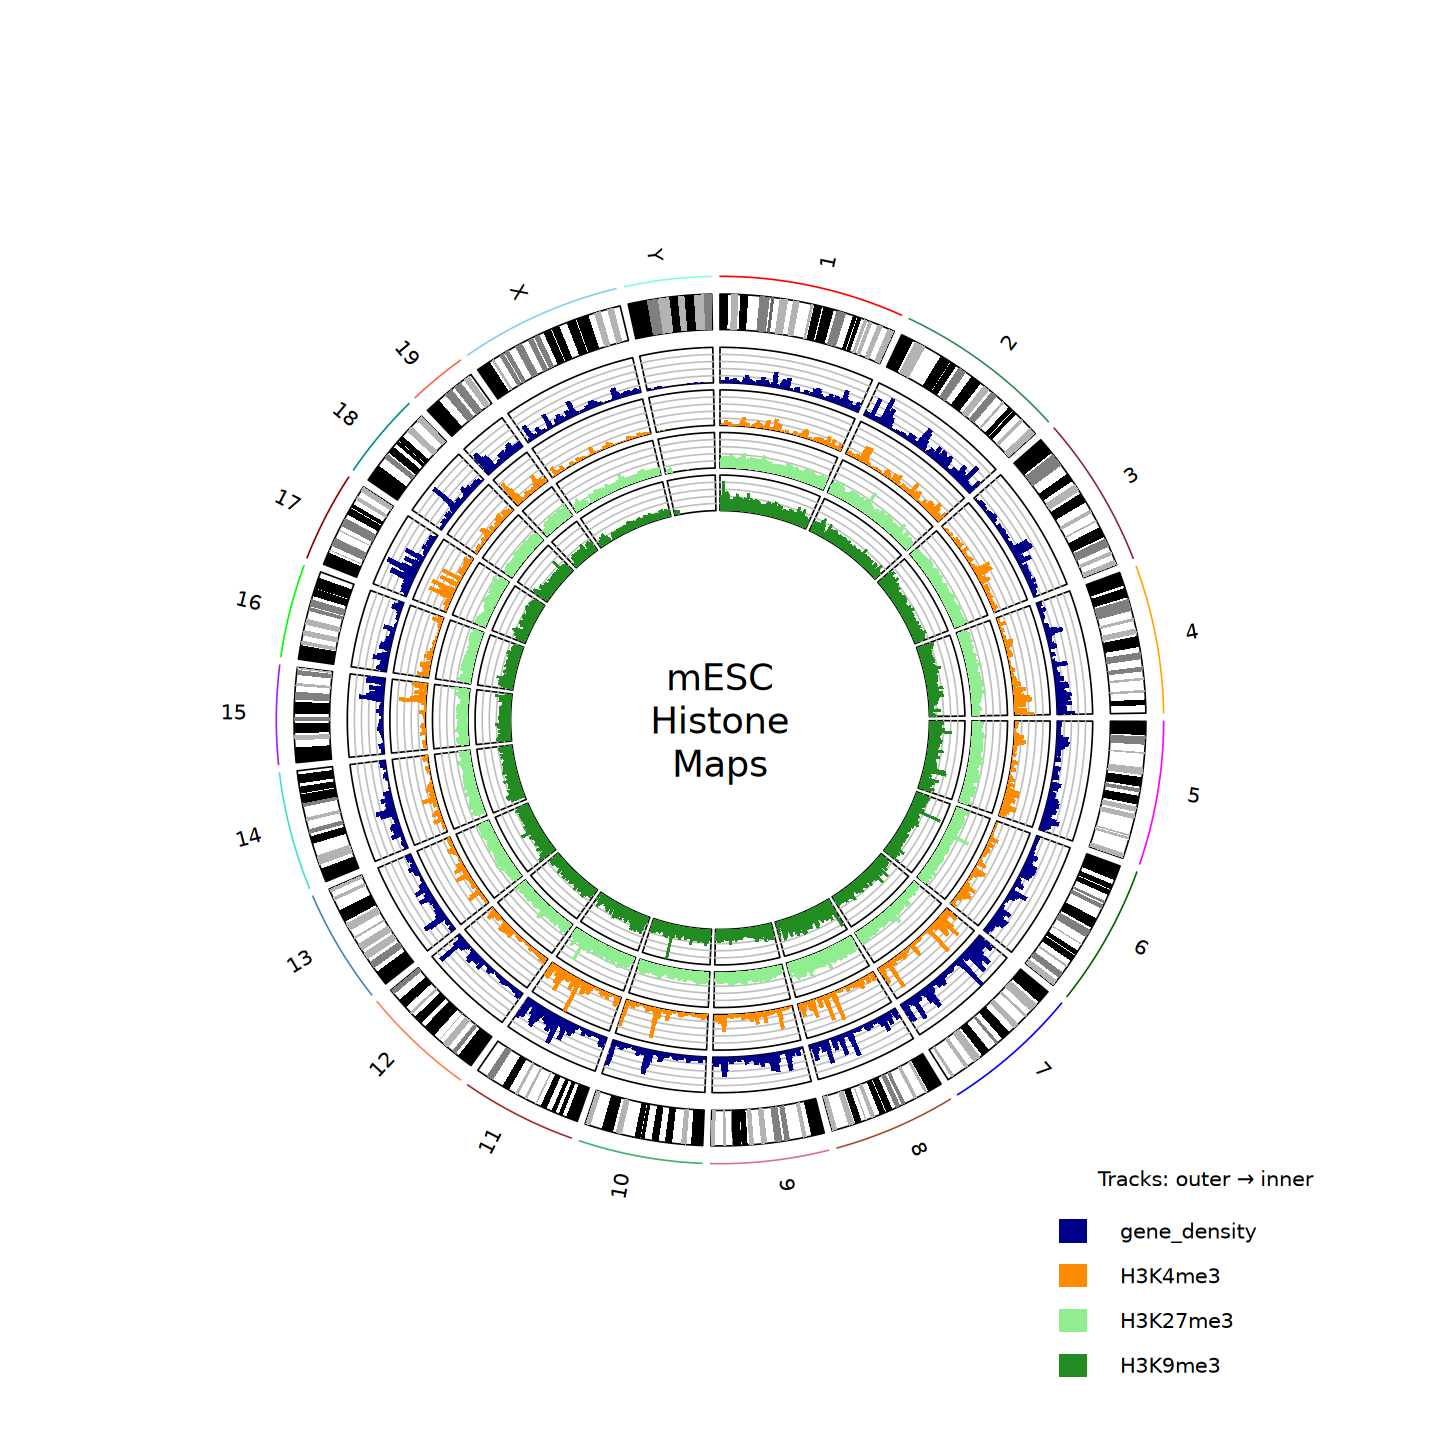

In [40]:
options(repr.plot.width = 12, repr.plot.height = 12)

# Initialize RCircos parameters
RCircos.Set.Core.Components(
    cyto.info = CytoBandIdeogram, 
    chr.exclude = NULL, 
    tracks.inside = length(track_colors), 
    tracks.outside = 0
)

params <- RCircos.Get.Plot.Parameters()
params$track.height <- 0.1
params$track.background <- "white"
params$text.size <- 0.8
RCircos.Reset.Plot.Parameters(params)

# Setup Plot Area
RCircos.Set.Plot.Area()

# Chromosome Ideogram
RCircos.Chromosome.Ideogram.Plot()

# Histograms Track
for (i in seq_along(track_colors)) {
    track <- names(track_colors)[i]
    params$hist.color <- track_colors[[track]]
    RCircos.Reset.Plot.Parameters(params)
    RCircos.Histogram.Plot(
        hist.data = bin_df,
        data.col = match(track, names(bin_df)),
        track.num = i,
        side = "in",
        min.value = 0,
        genomic.columns = 3,
        is.sorted = FALSE
    )
}

# Add center annotation text
text(0, 0, "mESC\nHistone\nMaps", cex = 1.8)

# Add legend
legend(
    "bottomright", 
    horiz = FALSE, 
    legend = names(track_colors), 
    fill = unname(track_colors), 
    border = NA, 
    bty = "n", 
    cex = 1, 
    title = "Tracks: outer → inner"
)

### c). ggbio

> R package for extending the grammar of graphics for genomic data
> - Yin, T., Cook, D. & Lawrence, M. ggbio: an R package for extending the grammar of graphics for genomic data. Genome Biol 13, R77 (2012). https://doi.org/10.1186/gb-2012-13-8-r77

### d). interacCircos

> The interacCircos package is designed for the generation of interactive Circos plot
> - Zhe Cui, Ya Cui, Tianyi Zang, Yadong Wang, interacCircos: an R package based on JavaScript libraries for the generation of interactive circos plots, Bioinformatics, Volume 37, Issue 20, October 2021, Pages 3642–3644, https://doi.org/10.1093/bioinformatics/btab232

## 3). Genomic Signal Plot

In [41]:
chrom_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chrom_idx]
chrom_bins <- tileGenome(
    chrom_sizes, tilewidth = 1e6, cut.last.tile.in.chrom = TRUE)

In [42]:
chrom_signals_list <- lapply(
    signals_list, keepSeqlevels, value = chrom_idx, pruning.mode = "coarse"
)

In [43]:
chrom_df <- bind_cols(
    chrom_bins |> 
        as.data.frame() |>
        dplyr::select(start, end),
    chrom_signals_list |>
        lapply(get_bin_means, bins = chrom_bins) |>
        as.data.frame(check.names = FALSE)
) |>
    pivot_longer(
        cols = all_of(MARKS), names_to = "marks", values_to = "score") |>
    mutate(
        marks = factor(marks, levels = MARKS), 
        position = (start + end) / 2, 
        plot_score = log1p(score)) |>
    arrange(marks, start) |>
    as.data.frame()

head(chrom_df)

,start,end,marks,score,position,plot_score
,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>
1,1,1000000,H3K4me3,0.0000000,500000.5,0.0000000
2,1000001,2000000,H3K4me3,0.0000000,1500000.5,0.0000000
3,2000001,3000000,H3K4me3,0.0000000,2500000.5,0.0000000
4,3000001,4000000,H3K4me3,0.6728741,3500000.5,0.5145431
5,4000001,5000000,H3K4me3,0.4782740,4500000.5,0.3908752
6,5000001,6000000,H3K4me3,0.9461384,5500000.5,0.6658471


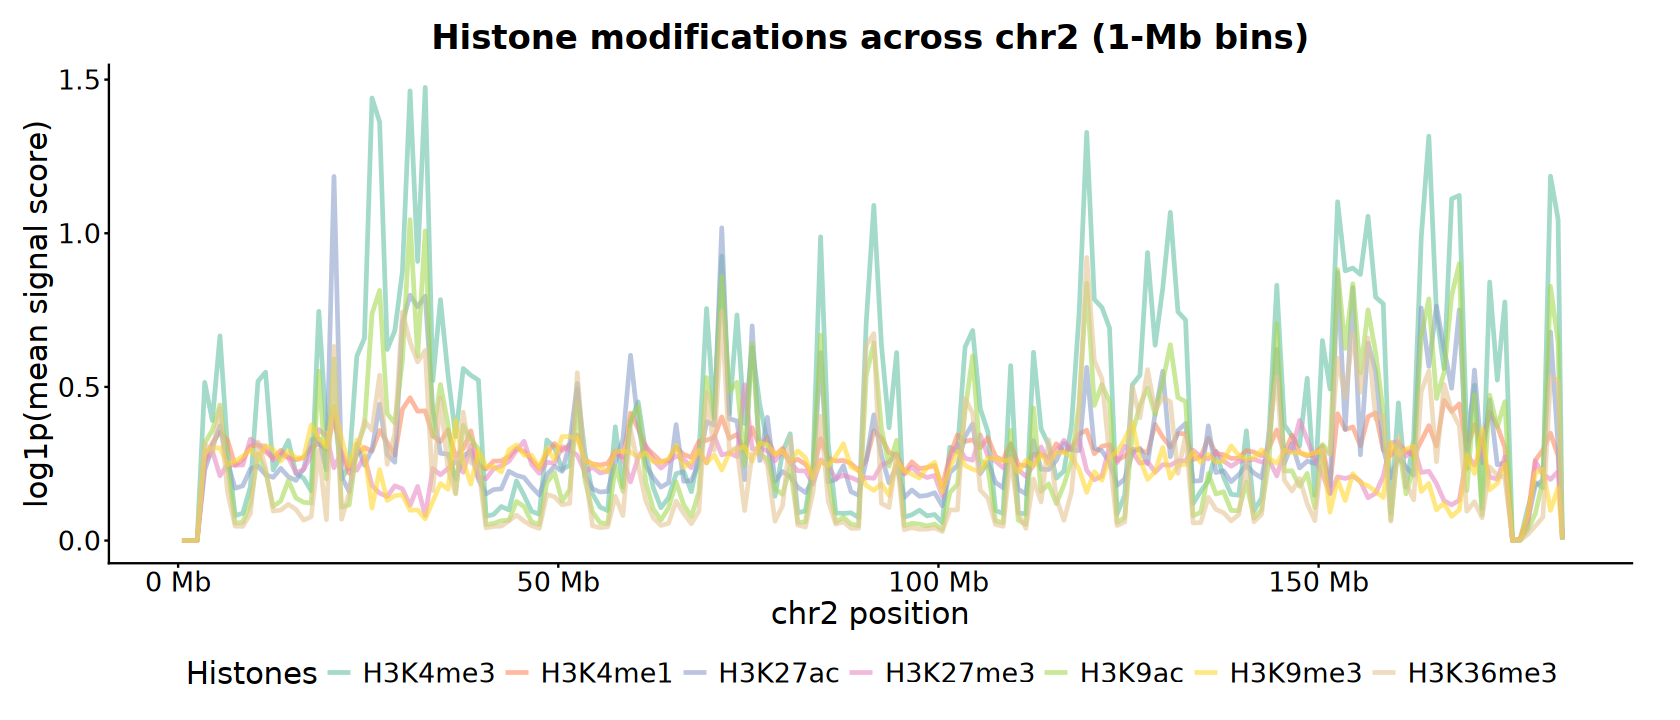

In [44]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(chrom_df, aes(x = position, y = plot_score, group = marks)) +
    geom_line(aes(color = marks), linewidth = 1, alpha = .6, na.rm = TRUE) +
    scale_x_continuous(
        limits = c(1, chrom_sizes), 
        breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 1)) +
    labs(
        title = paste0(
            "Histone modifications across ", chrom_idx, " (1-Mb bins)"),
        x = paste0(chrom_idx, " position"), 
        y = "log1p(mean signal score)",
        color = "Histones") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 2, 1, 1), "line"),
        legend.position = "bottom",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 5. Peak Annotation

### a). Manual

In [45]:
# gene <- genes(txdb)
gene <- transcripts(txdb)

In [46]:
feature_list <- list(
    TSS = promoters(gene, upstream = 0, downstream = 1), 
    Promoter = promoters(gene, upstream = 2000, downstream = 500), 
    Exon = exons(txdb), 
    Intron = unlist(intronsByTranscript(txdb), use.names = FALSE), 
    FiveUTR = unlist(fiveUTRsByTranscript(txdb), use.names = FALSE), 
    CDS = cds(txdb), 
    ThreeUTR = unlist(threeUTRsByTranscript(txdb), use.names = FALSE), 
    Downstream = flank(gene, width = 3000, start = FALSE)
)

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 3 out-of-bound ranges located on sequences
  chr4_JH584293_random, chr4_JH584295_random, and chr5_JH584296_random. Note
  that ranges located on a sequence whose length is unknown (NA) or on a
  circular sequence are not considered out-of-bound (use seqlengths() and
  isCircular() to get the lengths and circularity flags of the underlying
  sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 6 out-of-bound ranges located on sequences
  chr4_GL456350_random, chr4_JH584295_random, chr5_JH584298_random,
  chrX_GL456233_random, chrUn_GL456239, and chrUn_GL456385. Note that ranges
  located on a sequence whose length is unknown (NA) or on a circular sequence
  are not considered out-of-bound (use seqlengths() and isCircular() to get the
  len

In [47]:
annotate_peaks <- function(
    peaks, features, ignore.strand = TRUE,
    precedence = c("Promoter", "Exon", "Intron", "Intergenic")) {

    peaks$Annotation <- rep("Intergenic", length(peaks))
    
    for (feature in rev(setdiff(precedence, "Intergenic"))) {
        hit <- overlapsAny(
            peaks, features[[feature]], ignore.strand = ignore.strand)
        peaks$Annotation[hit] <- feature
    }

    position <- start(peaks) + (width(peaks) - 1L) %/% 2L

    if ("peak" %in% names(mcols(peaks))) {
        position <- start(peaks) + peaks$peak
    }

    anchor <- peaks
    ranges(anchor) <- IRanges(start = position, width = 1L)

    tss <- features$TSS
    idx <- nearest(anchor, tss, ignore.strand = ignore.strand)

    distance <- rep(NA_real_, length(peaks))
    matched <- which(!is.na(idx))
    direction <- c("+" = 1, "-" = -1)[
        as.character(strand(tss))[idx[matched]]]
    distance[matched] <- (
        position[matched] - start(tss)[idx[matched]]) * direction
    peaks$SignedDistToTSS <- distance

    return(peaks)
}

In [48]:
feature_order <- c(
    "Promoter", "FiveUTR", "ThreeUTR", "Exon", 
    "Intron", "Downstream", "Intergenic"
)

peaks_annotated_list <- lapply(
    peaks_list, 
    annotate_peaks, 
    features = feature_list, 
    precedence = feature_order
)

In [49]:
annotation_summary <- purrr::imap_dfr(peaks_annotated_list, function(gr, mark) {
    table(Feature = factor(gr$Annotation, levels = feature_order)) |>
        as.data.frame(responseName = "Count") |>
        mutate(
            Mark = mark, 
            Percentage = Count / length(gr) * 100)
    }) |>
    mutate(Mark = factor(Mark, levels = rev(MARKS))) |>
    dplyr::select(Mark, Feature, Count, Percentage)

head(annotation_summary)

,Mark,Feature,Count,Percentage
,<fct>,<fct>,<int>,<dbl>
1,H3K4me3,Promoter,30047,60.6042881
2,H3K4me3,FiveUTR,317,0.6393836
3,H3K4me3,ThreeUTR,1284,2.5898062
4,H3K4me3,Exon,2620,5.2844955
5,H3K4me3,Intron,7560,15.2483915
6,H3K4me3,Downstream,1045,2.1077472


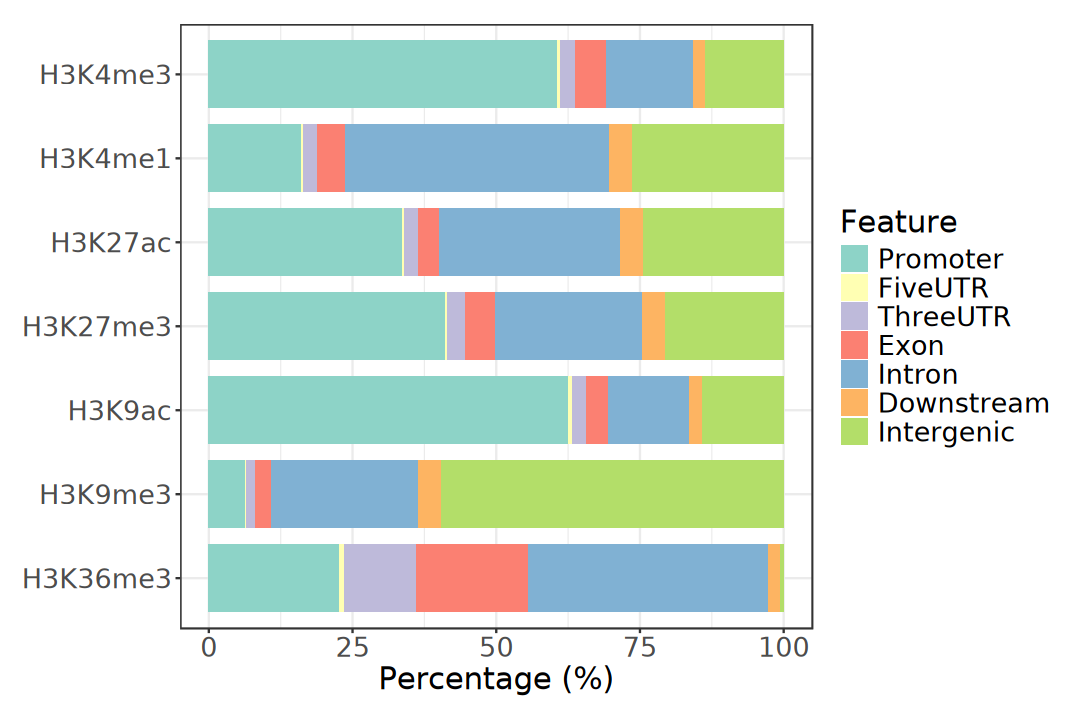

In [50]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(annotation_summary, aes(x = Mark, y = Percentage)) +
    geom_bar(
        aes(fill = Feature), stat = "identity", width = 0.8, 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [51]:
distance_colors <- c(
    "≤-10kb"   = "#2166ac",
    "-10~-3kb" = "#4393c3",
    "-3~-1kb"  = "#92c5de",
    "-1~0kb"   = "#d1e5f0",
    "0~1kb"    = "#fddbc7",
    "1~3kb"    = "#f4a582",
    "3~10kb"   = "#d6604d",
    ">10kb"    = "#b2182b"
)

In [52]:
tss_distance_summary <- purrr::imap_dfr(
    peaks_annotated_list, function(gr, mark) {
    
    distance <- cut(
        gr$SignedDistToTSS,
        breaks = c(-Inf, -10000, -3000, -1000, 0, 1000, 3000, 10000, Inf),
        labels = names(distance_colors),
        right = TRUE,
        include.lowest = TRUE
    )

    table(Distance = distance) |>
        as.data.frame(responseName = "Count") |>
        mutate(
            Mark = mark,
            Percentage = Count / sum(Count) * 100)
}) |>
    mutate(Mark = factor(Mark, levels = rev(MARKS))) |>
    dplyr::select(Mark, Distance, Count, Percentage)

head(tss_distance_summary)

,Mark,Distance,Count,Percentage
,<fct>,<fct>,<int>,<dbl>
1,H3K4me3,≤-10kb,3534,7.128018
2,H3K4me3,-10~-3kb,3037,6.125577
3,H3K4me3,-3~-1kb,2312,4.663265
4,H3K4me3,-1~0kb,10545,21.269086
5,H3K4me3,0~1kb,18208,36.725226
6,H3K4me3,1~3kb,4182,8.435023


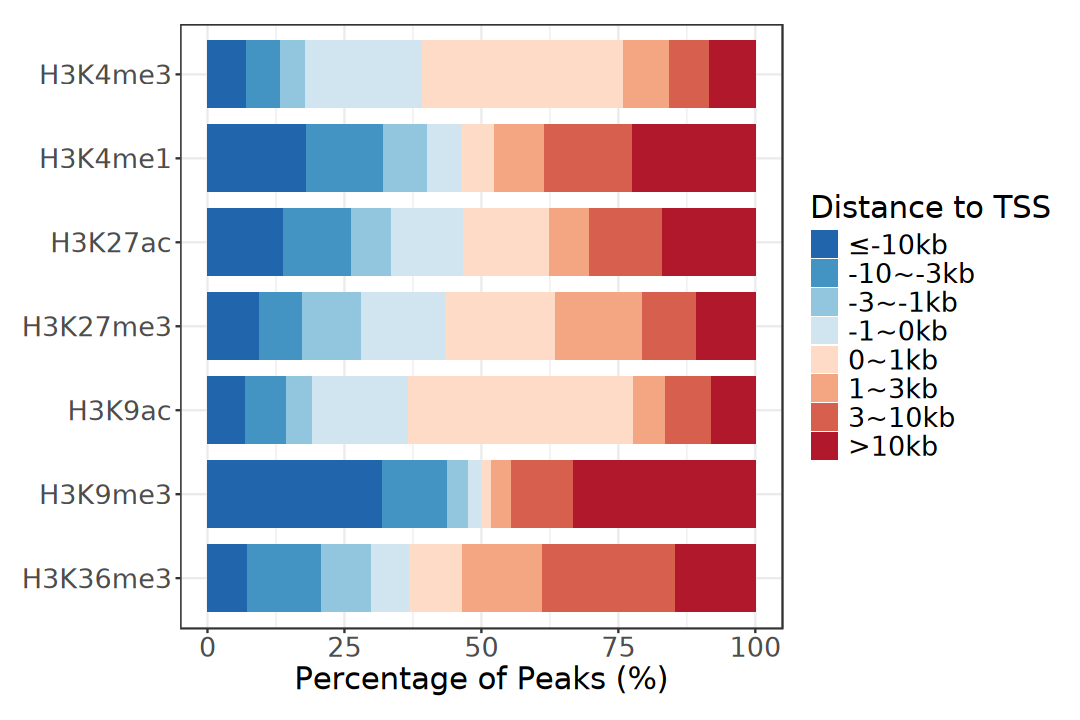

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(tss_distance_summary, aes(x = Mark, y = Percentage)) +
    geom_bar(
        aes(fill = Distance), stat = "identity", width = 0.8, 
        position = position_stack(reverse = TRUE)) +
    scale_fill_manual(values = distance_colors, name = "Distance to TSS") +
    labs(x = NULL, y = "Percentage of Peaks (%)") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### b). ChIPseeker

In [54]:
suppressPackageStartupMessages(library(ChIPseeker))

In [55]:
# Downstream within 3kb
feature_order <- c(
    "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
    "Downstream", "Intergenic"
)

peaks_annotated_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    level = "transcript", 
    tssRegion = c(-2000, 500), 
    genomicAnnotationPriority = feature_order, 
    verbose = FALSE
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


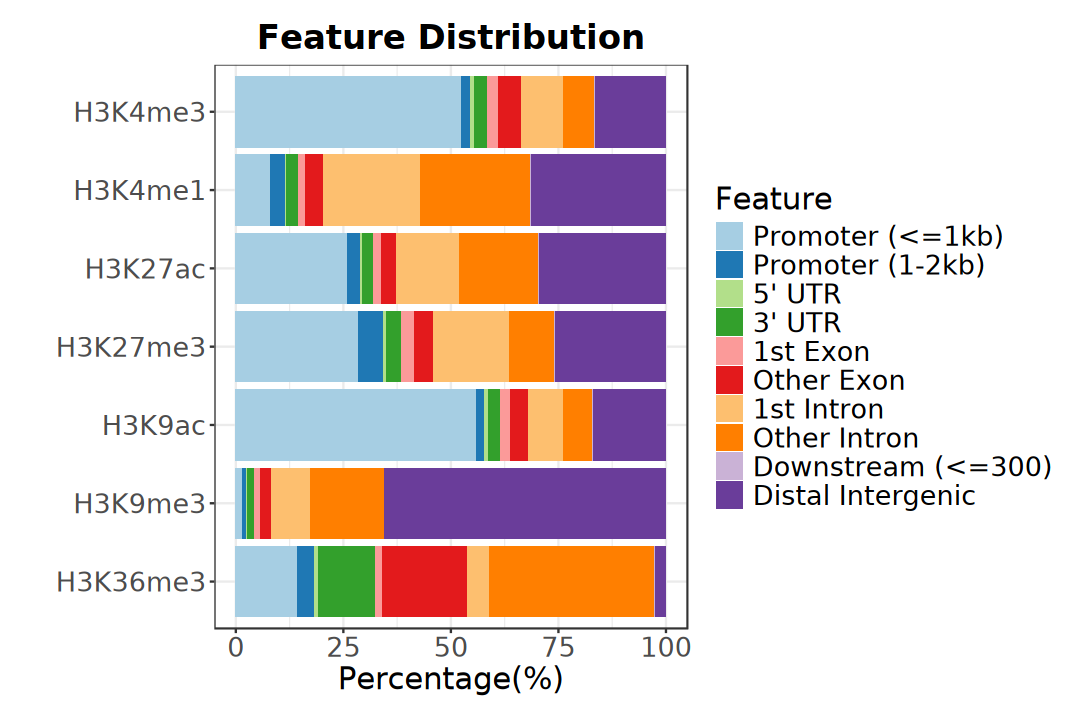

In [56]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_annotated_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

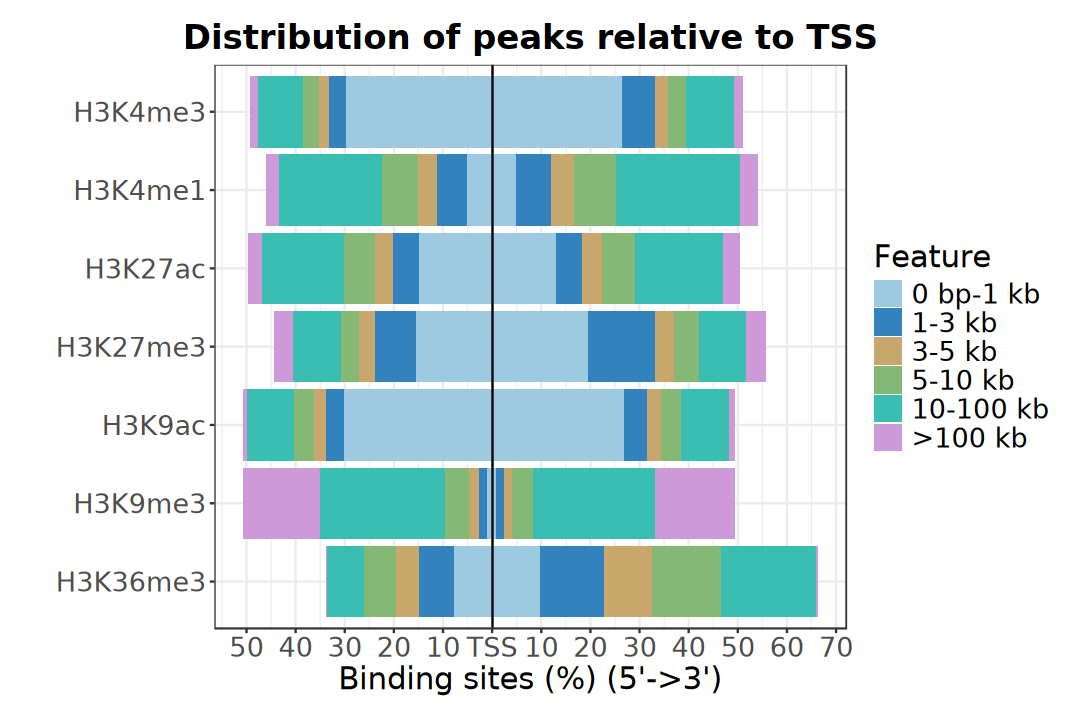

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDistToTSS(
    peaks_annotated_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### c). ChIPpeakAnno

In [58]:
suppressPackageStartupMessages(library(ChIPpeakAnno))

In [59]:
feature_order <- c(
    "Promoters", "fiveUTRs", "threeUTRs", "Exons",
    "Introns", "immediateDownstream"
)

peaks_annotated_list <- lapply(
    peaks_list, 
    assignChromosomeRegion, 
    TxDb = txdb, 
    nucleotideLevel = FALSE, 
    proximal.promoter.cutoff = c(upstream = 2000, downstream = 500), 
    immediate.downstream.cutoff = c(upstream = 0, downstream = 3000), 
    precedence = feature_order
)

In [60]:
annotation_summary <- purrr::imap_dfr(
    peaks_annotated_list, function(anno, mark) {
        data.frame(
            Mark = mark,
            Feature = names(anno$percentage),
            Percentage = as.numeric(anno$percentage))
}) |>
    mutate(
        Mark = factor(Mark, levels = rev(MARKS)),
        Feature = Feature |> 
            factor(levels = c(feature_order, "Intergenic.Region"))) |>
    dplyr::select(Mark, Feature, Percentage)

head(annotation_summary)

,Mark,Feature,Percentage
,<fct>,<fct>,<dbl>
1,H3K4me3,Promoters,60.6042881
2,H3K4me3,fiveUTRs,0.6393836
3,H3K4me3,threeUTRs,2.5898062
4,H3K4me3,Exons,5.2844955
5,H3K4me3,Introns,15.2483915
6,H3K4me3,immediateDownstream,2.1077472


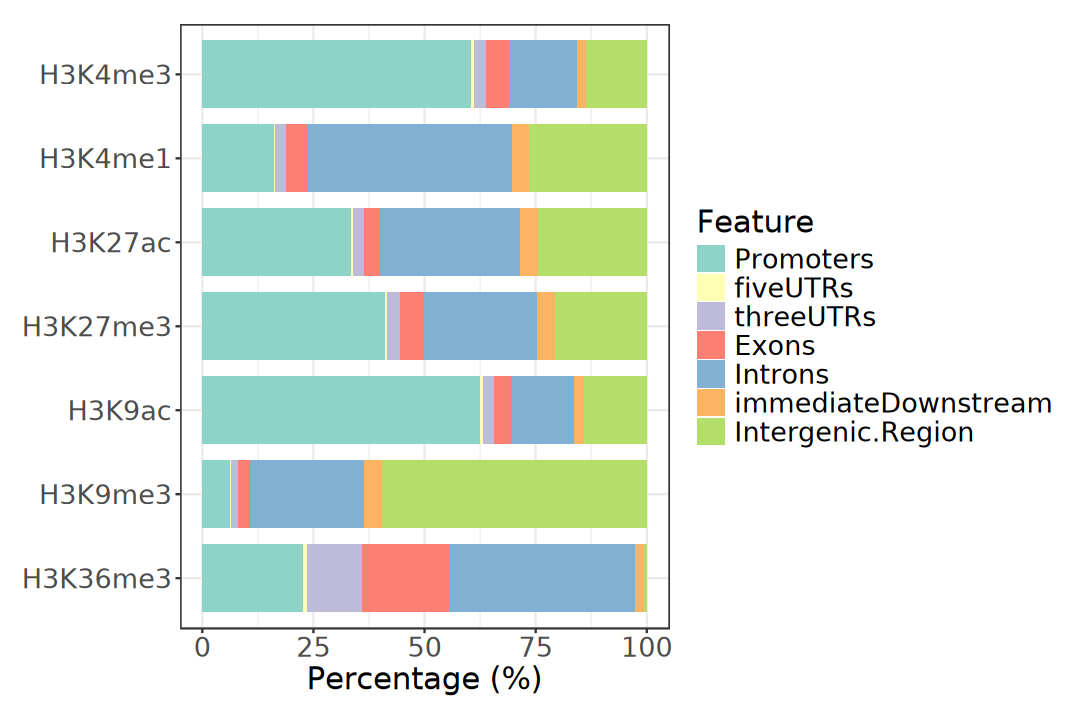

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(annotation_summary, aes(x = Mark, y = Percentage)) +
    geom_bar(
        aes(fill = Feature), stat = "identity", width = 0.8, 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. Histone Modification Profiles

## 1). [deepTools](https://github.com/deeptools/deeptools)

## 2). EnrichedHeatmap

In [62]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [63]:
GENES <- genes(txdb)

  66 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [64]:
# ~ 12 minutes
gene_mat_list <- lapply(
    signals_list, 
    normalizeToMatrix, 
    GENES, 
    value_column = "score", 
    mean_mode = "w0", 
    extend = 2000, 
    w = 50, 
    target_ratio = 0.4, 
    background = 0, 
    smooth = FALSE
)

In [65]:
gene_order <- order(
    enriched_score(gene_mat_list[["H3K4me3"]]),
    decreasing = TRUE
)

In [66]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(gene_mat_list)) |> 
    setNames(names(gene_mat_list)
)

color_fun <- lapply(names(gene_mat_list), function(mark) {
    limit <- gene_mat_list[[mark]] |>
        quantile(0.99, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, limit), c("#FFFFFF", mark_colors[[mark]]))
})

names(color_fun) <- names(gene_mat_list)

In [67]:
ht_list <- lapply(names(gene_mat_list), function(mark) {
    EnrichedHeatmap(
        gene_mat_list[[mark]], 
        name = mark, 
        column_title = mark, 
        col = color_fun[[mark]], 
        cluster_rows = FALSE, 
        row_order = gene_order, 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        width = unit(4, "cm"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = mark_colors[mark]), 
                axis_param = list(gp = gpar(fontsize = 10))
            ), 
            height = unit(3, "cm"), 
            show_legend = FALSE
        ), 
        show_heatmap_legend = TRUE, 
        heatmap_legend_param = list(
            title = "Signal p-value", 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")
        ), 
        use_raster = TRUE)
})

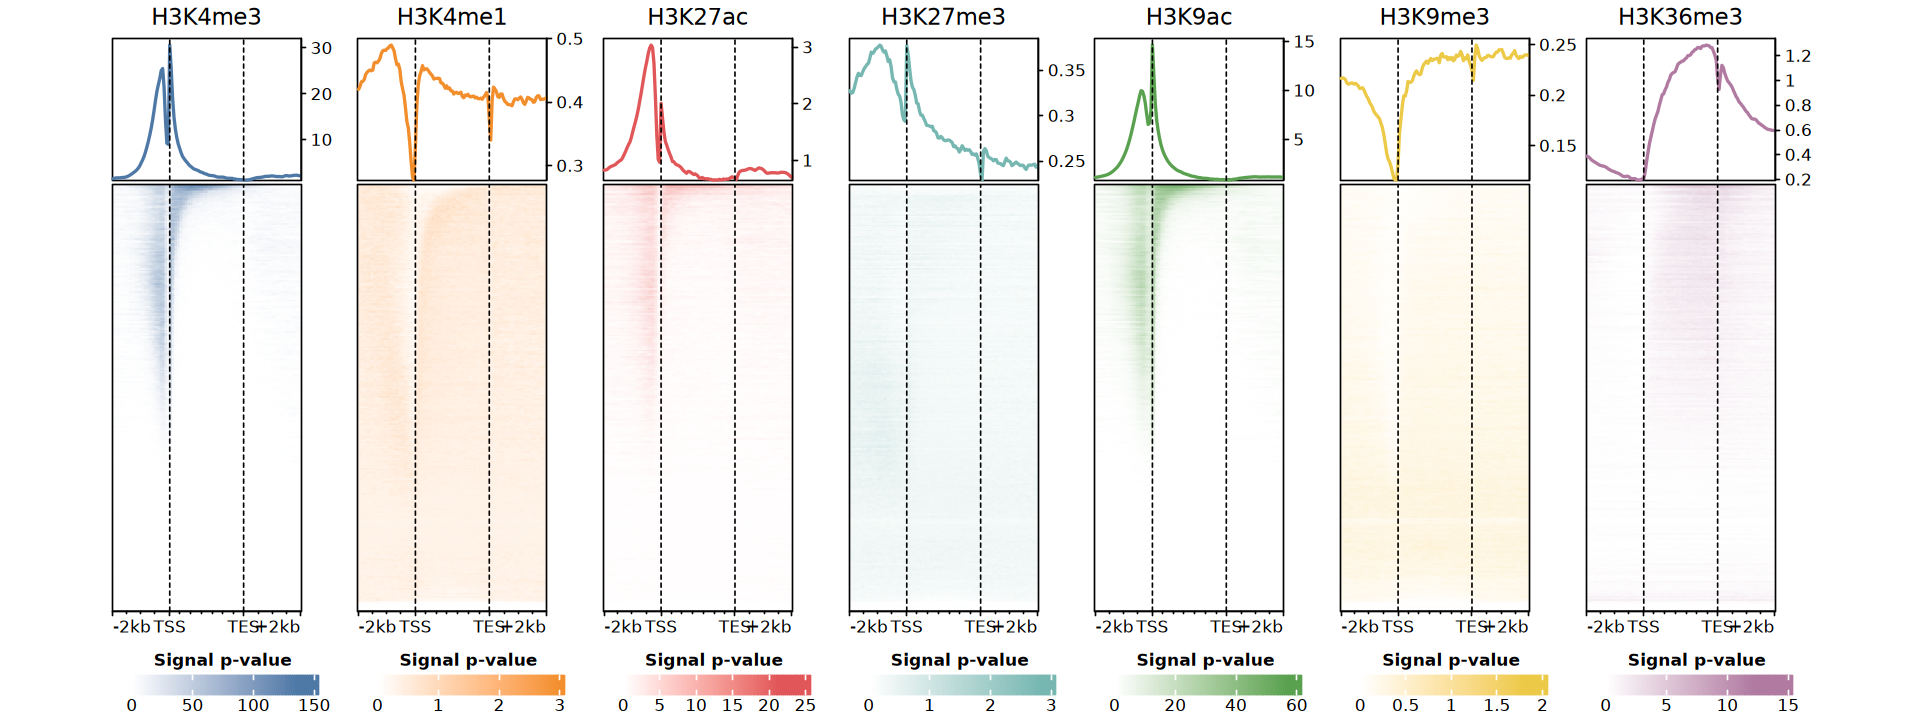

In [68]:
options(repr.plot.width = 16, repr.plot.height = 6)

draw(
    Reduce(`+`, ht_list), 
    heatmap_legend_side = "bottom", 
    ht_gap = unit(12, "mm"), 
    legend_gap = unit(12, "mm")
)

In [69]:
limit <- unlist(gene_mat_list, use.names = FALSE) |>
    quantile(0.99, na.rm = TRUE)

color_fun <- circlize::colorRamp2(c(0, limit), c("#F5F5F5", "#FF3F56"))

In [70]:
ht_list <- lapply(names(gene_mat_list), function(mark) {
    EnrichedHeatmap(
        gene_mat_list[[mark]], 
        name = mark, 
        column_title = mark, 
        col = color_fun, 
        cluster_rows = FALSE, 
        row_order = gene_order, 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        width = unit(4, "cm"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = mark_colors[mark]), 
                ylim = c(0, limit), 
                axis_param = list(gp = gpar(fontsize = 10))
            ), 
            height = unit(3, "cm"), 
            show_legend = FALSE
        ), 
        show_heatmap_legend = TRUE, 
        heatmap_legend_param = list(
            title = "Signal p-value", 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")
        ), 
        use_raster = TRUE)
})

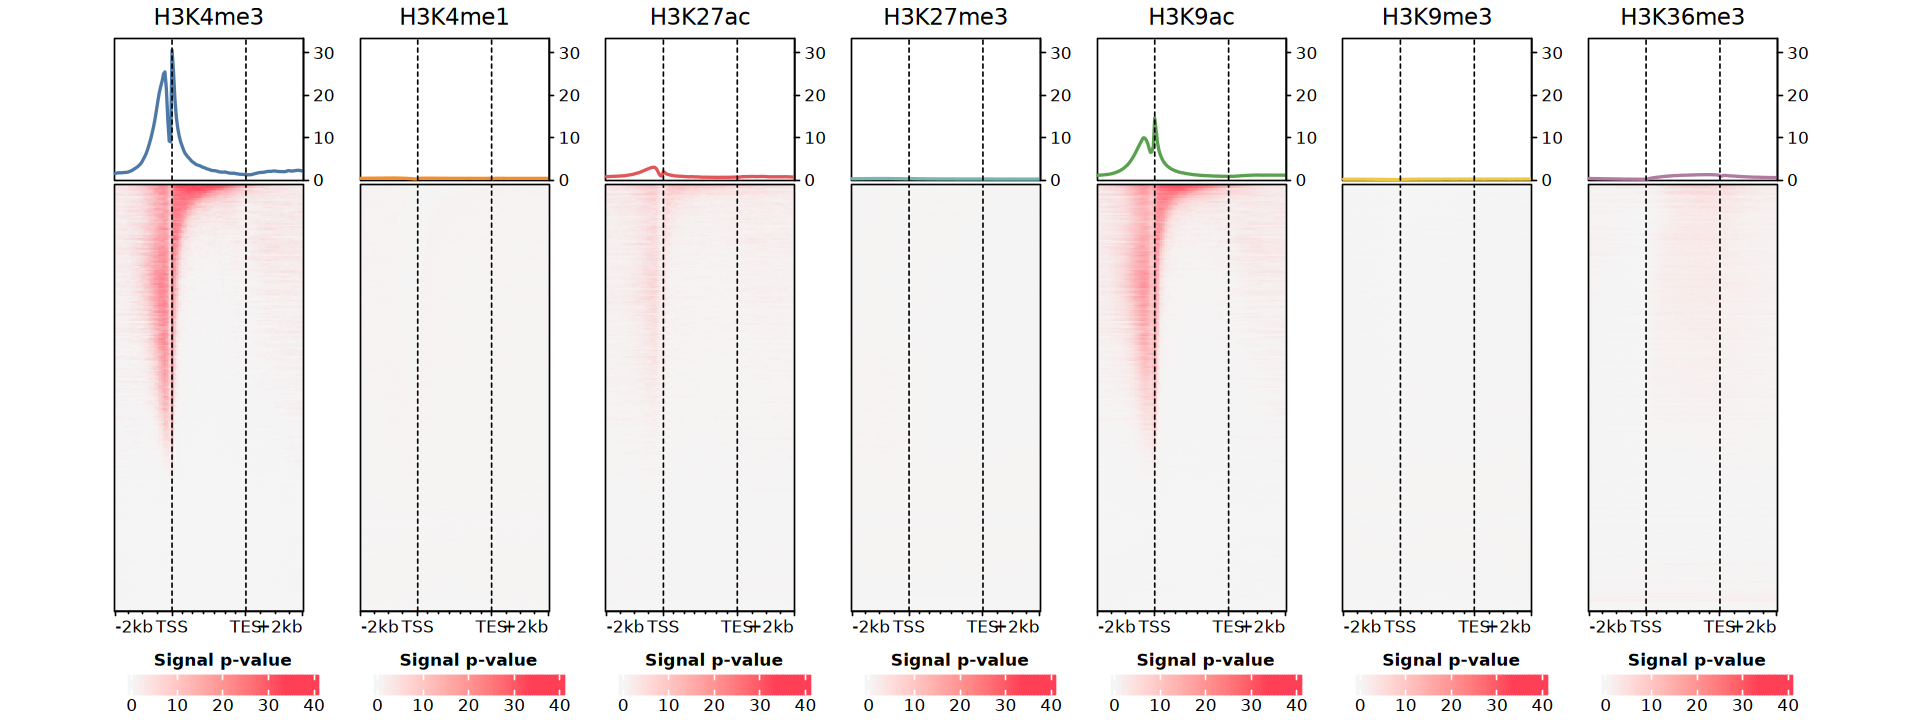

In [71]:
options(repr.plot.width = 16, repr.plot.height = 6)

draw(
    Reduce(`+`, ht_list), 
    heatmap_legend_side = "bottom", 
    ht_gap = unit(12, "mm"), 
    legend_gap = unit(12, "mm")
)

In [72]:
profiles_df <- purrr::imap_dfr(
    lapply(gene_mat_list, colMeans, na.rm = TRUE),
    function(signal, mark) {
        data.frame(
            Position = seq_along(signal),
            Mark = mark,
            Signal = as.numeric(signal))
}) |>
    mutate(Mark = factor(Mark, levels = MARKS))

In [73]:
mat <- gene_mat_list[[1L]]
target_index <- attr(mat, "target_index")

tss_position <- min(target_index) - 0.5
tes_position <- max(target_index) + 0.5

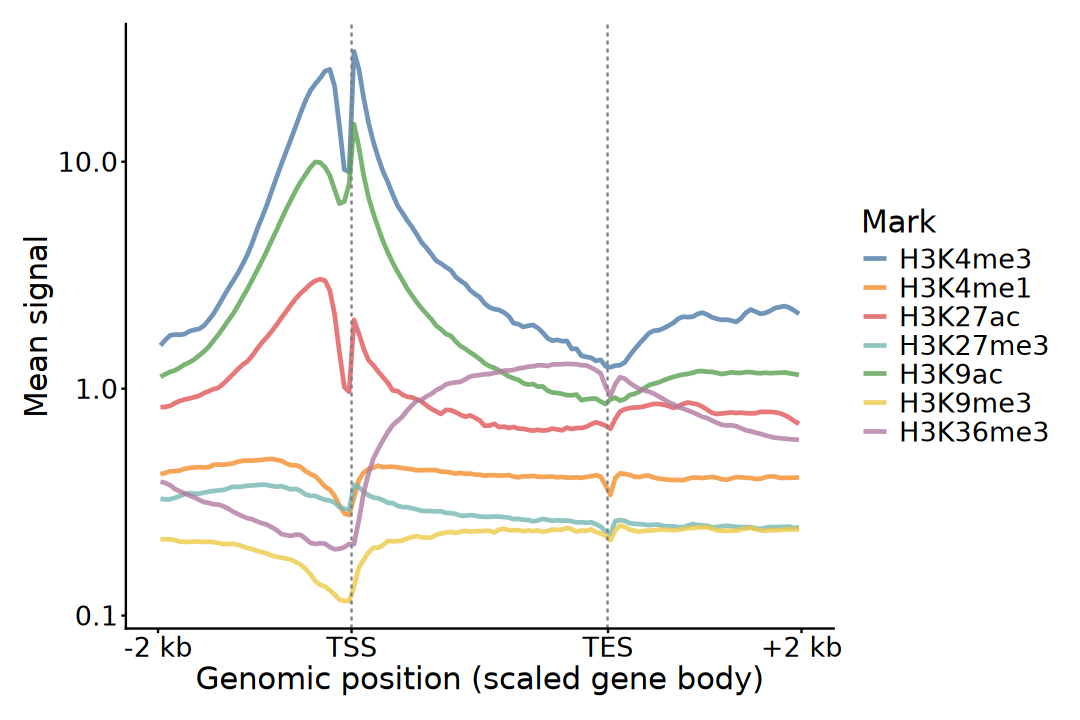

In [74]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Signal, color = Mark)) +
    geom_line(linewidth = 1, alpha = 0.8) +
    geom_vline(
        xintercept = c(tss_position, tes_position), 
        linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        limits = c(0.5, ncol(mat) + 0.5),
        breaks = c(0.5, tss_position, tes_position, ncol(mat) + 0.5),
        labels = c("-2 kb", "TSS", "TES", "+2 kb")) +
    scale_y_log10() +
    scale_color_manual(values = mark_colors) +
    labs(
        x = "Genomic position (scaled gene body)", 
        y = "Mean signal", 
        color = "Mark") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 7. Genome Browser Snapshots

In [75]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [76]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [77]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [78]:
# Hoxa
genome_id = "mm10"

target_region <- "chr6:52150000-52300000"

target_region <- str_match(target_region, "^([^:]+):(\\d+)-(\\d+)$") |>
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), end = as.numeric(V4)) |>
    column_to_rownames("pos") |>
    GRanges()

chrom <- seqnames(target_region) |> as.character()
region_start <- start(target_region)
region_end <- end(target_region)

target_region

GRanges object with 1 range and 0 metadata columns:
                         seqnames            ranges strand
                            <Rle>         <IRanges>  <Rle>
  chr6:52150000-52300000     chr6 52150000-52300000      *
  -------
  seqinfo: 1 sequence from an unspecified genome; no seqlengths

In [79]:
id_track <- IdeogramTrack(
    chromosome = chrom, 
    genome = genome_id, 
    bands = bands, 
    name = str_to_title(chrom), 
    fontcolor = "black", 
    fontsize = 20
)

scale_track <- GenomeAxisTrack(
    scale = 0.1, 
    col = "black", 
    fontcolor = "black", 
    labelPos = "above", 
    showTitle = FALSE, 
    fontsize = 16,
    distFromAxis = 1, 
    lwd = 1
)

axis_track <- GenomeAxisTrack(
    labelPos = "above", 
    col = "black", 
    fontcolor = "black", 
    exponent = 6, 
    distFromAxis = 0.5, 
    showTitle = FALSE, 
    fontsize = 14, 
    lwd = 2
)

In [ ]:
mark_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_list)) |> 
    setNames(names(signals_list)
)

In [81]:
signal_tracks <- purrr::imap(signals_list, function(gr, mark) {
    gr <- subsetByOverlaps(
        gr, target_region, ignore.strand = TRUE)

    DataTrack(
        range = gr,
        data = "score",
        name = mark,
        type = "histogram",
        chromosome = chrom,
        genome = genome_id,
        showTitle = TRUE,
        fontsize = 12,
        cex.title = 1,
        cex.axis = 0.8,
        col.title = "black",
        fontcolor.title = "black",
        col.histogram = mark_colors[[mark]],
        fill.histogram = mark_colors[[mark]]
    )
})

In [82]:
gene_track <- GeneRegionTrack(
    txdb, 
    genome = genome_id, 
    chromosome = chrom, 
    start = region_start, 
    end = region_end,
    transcriptAnnotation = "symbol", 
    showId = TRUE, 
    geneSymbol = TRUE, 
    collapseTranscripts = "longest", 
    name = "Gene", 
    col = "grey50", 
    fill = "orange", 
    fontcolor.group = "black", 
    fontsize = 20, 
    fontsize.group = 16, 
    cex.title = 1, 
    rotation.title = 0,
    stacking = "squish"
)

In [83]:
gene_ranges <- ranges(gene_track)
gene_ids <- as.character(gene_ranges$gene)

# Entrez ID → Gene Symbol
gene_symbols <- AnnotationDbi::mapIds(
    org.Mm.eg.db,
    keys = unique(gene_ids),
    column = "SYMBOL",
    keytype = "ENTREZID",
    multiVals = "first"
)

symbols <- unname(gene_symbols[gene_ids])
symbols[is.na(symbols)] <- gene_ids[is.na(symbols)]

gene_ranges$symbol <- symbols
ranges(gene_track) <- gene_ranges

'select()' returned 1:1 mapping between keys and columns



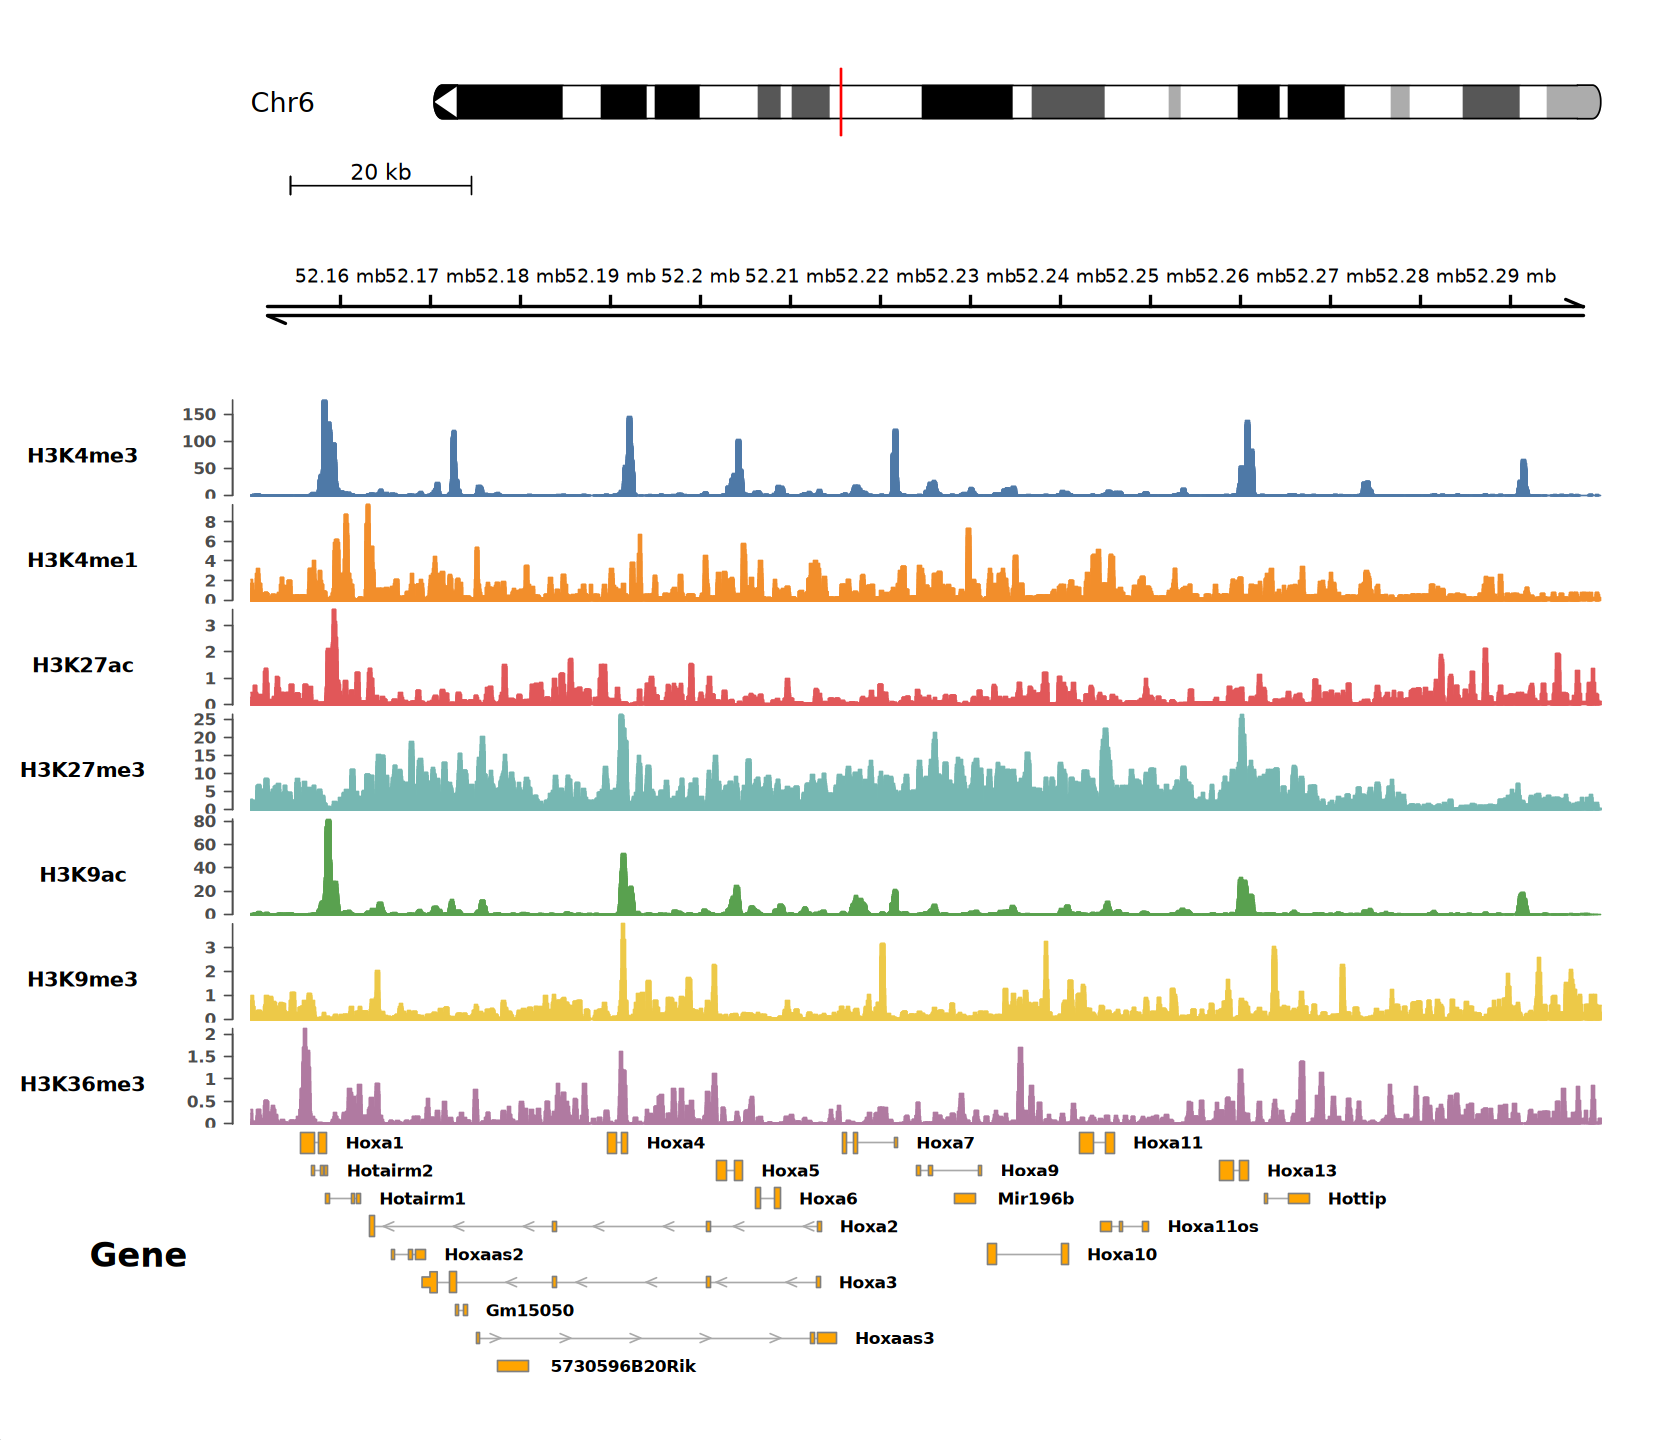

In [84]:
options(repr.plot.width = 14, repr.plot.height = 12)

track_list <- c(
    list(id_track, scale_track, axis_track),
    signal_tracks,
    list(gene_track)
)

plotTracks(
    trackList = track_list, 
    chromosome = chrom, 
    from = region_start, 
    to = region_end, 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 6), 
    background.title = "white", 
    col.title = "black", 
    col.axis = "grey30", 
    reverseStrand = FALSE, 
    rotation.title = 0, 
    title.width = 1, 
    just.group = "right", 
    extend.left = 0, 
    margin = 20
)

# * Reference